# Day 7: Production Inference Engine, Real-Time REST API, Interactive Web Dashboard, Docker Containerization & CI/CD Automated Testing Framework
**Project:** Wine Quality Prediction (Cortez et al. UCI Machine Learning Repository)
**Author:** ML Engineering & Production Deployment Team
**Date:** October 21, 2026
**Tech Stack:** Python 3.14, FastAPI, Uvicorn, Pydantic v2, Streamlit, Pytest, Docker, Docker-Compose, GitHub Actions, Scikit-learn, Joblib, Plotly, Seaborn, Matplotlib

## Objectives for Day 7
1. **Production Inference Service & Domain Feature Synthesis (`src/production_service.py`):**
   - Encapsulate the serialized champion Random Forest ensemble into a hardened serving layer.
   - Automatically derive 5 biochemical interaction features (`total_acidity`, `bound_sulfur_dioxide`, `free_to_total_so2_ratio`, `alcohol_to_density_ratio`, `sulphate_to_chloride_ratio`).
   - Synthesize enological cellar directives and 4 commercial sensory tiers (*Grand Reserve*, *Reserve Grade*, *Table Standard*, *Commercial Bulk*).
2. **Pydantic v2 Data Contract & Boundary Enforcement:**
   - Implement rigorous schemas with strict biological/physical bounds and cross-attribute consistency checks (e.g. Total SO₂ $\ge$ Free SO₂).
3. **High-Throughput Vectorized Batch Inference:**
   - Provide batch inference endpoints capable of evaluating thousands of winery specimens concurrently.
4. **Empirical Latency & Scaling Benchmarks:**
   - Profile single-sample and batch latency percentiles (P50, P90, P95, P99) and throughput scaling curves.
5. **Interactive Web Dashboard (`src/interactive_dashboard.py`):**
   - Build a Streamlit application featuring live parameter tuning, radar profiling against reserve benchmarks, batch CSV uploads, and downloadable lab reports.
6. **Automated Comprehensive Pytest Suite (`tests/`):**
   - Implement and execute 22 unit and integration tests covering data integrity, schema validation, feature parity, API contracts, threshold overrides, and latency budgets.
7. **Containerization & CI/CD Pipeline:**
   - Deliver multi-stage `Dockerfile`, `docker-compose.yml`, and GitHub Actions workflow (`.github/workflows/mlops_pipeline.yml`).

In [1]:
import sys
import os
import json
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown

warnings.filterwarnings('ignore')

# Ensure repository root is on sys.path
REPO_ROOT = Path('.').resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.production_service import (
    WineQualityInferenceService,
    WinePhysicochemicalInput,
    derive_interaction_features,
    get_test_client,
    DEFAULT_MODEL_PATH,
    DEFAULT_METADATA_PATH,
    RECOMMENDED_SCREENING_THRESHOLD
)
from src.data_loader import load_wine_data

print('Day 7 Environment and Serving Modules Initialized Successfully!')

Day 7 Environment and Serving Modules Initialized Successfully!


## 1. Champion Model Artifact & Metadata Provenance Inspection
Before exposing endpoints to production traffic, we verify the integrity of serialized artifacts on disk (`models/champion_rf_pipeline.joblib` and `models/champion_rf_pipeline.json`).

In [2]:
service = WineQualityInferenceService()
print(f'Model Ready: {service.is_ready}')
print(f'Artifact Path: {service.model_path}')

with open(DEFAULT_METADATA_PATH, 'r') as f:
    meta = json.load(f)

meta_df = pd.DataFrame([
    {'Parameter': 'Model Name', 'Value': meta.get('model_name')},
    {'Parameter': 'Date Finalized', 'Value': meta.get('date_finalized')},
    {'Parameter': 'Number of Trees', 'Value': meta.get('n_estimators')},
    {'Parameter': 'Max Depth', 'Value': meta.get('max_depth')},
    {'Parameter': 'Class Weighting', 'Value': meta.get('class_weight')},
    {'Parameter': 'Features Expected', 'Value': meta.get('num_features')},
    {'Parameter': 'Holdout Test ROC-AUC', 'Value': f"{meta.get('test_roc_auc'):.4f}"},
    {'Parameter': 'Holdout Test PR-AUC', 'Value': f"{meta.get('test_pr_auc'):.4f}"},
    {'Parameter': 'Screening Threshold (tau)', 'Value': meta.get('operating_screening_threshold')}
])
display(meta_df)

Model Ready: True
Artifact Path: models\champion_rf_pipeline.joblib


,Parameter,Value
0,Model Name,Tuned Random Forest Classifier
1,Date Finalized,2026-10-08
2,Number of Trees,200
3,Max Depth,18
4,Class Weighting,balanced
5,Features Expected,16
6,Holdout Test ROC-AUC,0.9368
7,Holdout Test PR-AUC,0.8095
8,Screening Threshold (tau),0.35


## 2. Pydantic v2 Data Contract Validation & Exception Handling
Data validation is the first line of defense in production ML systems. We verify that:
- Valid physicochemical inputs parse correctly.
- Biologically impossible or out-of-bounds parameters raise explicit validation errors.
- Contradictory inputs (e.g. Free SO₂ > Total SO₂) are intercepted before feature synthesis.

In [3]:
from pydantic import ValidationError

# 1. Valid Input Sample
valid_payload = {
    'sample_id': 'LOT-2026-VAL-001',
    'fixed acidity': 8.8,
    'volatile acidity': 0.34,
    'citric acid': 0.42,
    'residual sugar': 2.1,
    'chlorides': 0.071,
    'free sulfur dioxide': 19.0,
    'total sulfur dioxide': 38.0,
    'density': 0.9954,
    'pH': 3.31,
    'sulphates': 0.84,
    'alcohol': 12.3
}
parsed_specimen = WinePhysicochemicalInput(**valid_payload)
print('Valid Sample Parsed Successfully:', parsed_specimen.sample_id)

# 2. Intercepting Invalid Range (e.g. Negative pH)
try:
    invalid_payload = dict(valid_payload, pH=1.2)
    WinePhysicochemicalInput(**invalid_payload)
except ValidationError as e:
    print('Successfully intercepted invalid pH:', e.errors()[0]['msg'])

# 3. Intercepting SO2 Cross-Attribute Contradiction
try:
    contradictory_payload = dict(valid_payload, **{'free sulfur dioxide': 50.0, 'total sulfur dioxide': 20.0})
    WinePhysicochemicalInput(**contradictory_payload)
except ValidationError as e:
    print('Successfully intercepted SO2 contradiction:', e.errors()[0]['msg'])

Valid Sample Parsed Successfully: LOT-2026-VAL-001
Successfully intercepted invalid pH: Input should be greater than or equal to 2.6
Successfully intercepted SO2 contradiction: Value error, total_sulfur_dioxide (20.0) cannot be less than free_sulfur_dioxide (50.0)


## 3. Real-Time Single-Sample Prediction & Cellar Guidance
We test single-sample inference comparing an everyday table wine against a candidate reserve wine.

In [4]:
table_wine = WinePhysicochemicalInput(
    sample_id='SAMPLE-TABLE-01',
    fixed_acidity=7.2, volatile_acidity=0.62, citric_acid=0.08, residual_sugar=1.8,
    chlorides=0.084, free_sulfur_dioxide=10.0, total_sulfur_dioxide=55.0, density=0.9972,
    pH=3.45, sulphates=0.52, alcohol=9.4
)

reserve_wine = WinePhysicochemicalInput(
    sample_id='SAMPLE-RESERVE-01',
    fixed_acidity=9.5, volatile_acidity=0.28, citric_acid=0.52, residual_sugar=2.2,
    chlorides=0.062, free_sulfur_dioxide=22.0, total_sulfur_dioxide=36.0, density=0.9948,
    pH=3.28, sulphates=0.86, alcohol=12.8
)

res_table = service.predict_single(table_wine)
res_reserve = service.predict_single(reserve_wine)

comparison_df = pd.DataFrame([
    {
        'Sample ID': res_table.sample_id,
        'Verdict': res_table.prediction_label,
        'Sensory Tier': res_table.sommelier_grade,
        'Probability (>=7)': f'{res_table.probability_good * 100:.1f}%',
        'Total Acidity': res_table.engineered_features['total_acidity'],
        'Alc/Density': res_table.engineered_features['alcohol_to_density_ratio'],
        'Cellar Recommendation': res_table.decision_guidance
    },
    {
        'Sample ID': res_reserve.sample_id,
        'Verdict': res_reserve.prediction_label,
        'Sensory Tier': res_reserve.sommelier_grade,
        'Probability (>=7)': f'{res_reserve.probability_good * 100:.1f}%',
        'Total Acidity': res_reserve.engineered_features['total_acidity'],
        'Alc/Density': res_reserve.engineered_features['alcohol_to_density_ratio'],
        'Cellar Recommendation': res_reserve.decision_guidance
    }
])
display(comparison_df)

,Sample ID,Verdict,Sensory Tier,Probability (>=7),Total Acidity,Alc/Density,Cellar Recommendation
0,SAMPLE-TABLE-01,Normal Wine (Score < 7),Commercial Bulk,0.5%,7.82,9.4264,Low reserve probability. Recommended for secon...
1,SAMPLE-RESERVE-01,Good / Premium Wine (Score >= 7),Grand Reserve,93.5%,9.78,12.8669,Exceptional enological balance. Top candidate ...


## 4. High-Throughput Vectorized Laboratory Batch Scoring
We simulate a commercial laboratory run by scoring 50 wine vats sampled from the dataset.

In [5]:
df_raw = load_wine_data(wine_type='red').sample(50, random_state=42).reset_index(drop=True)
batch_inputs = [
    WinePhysicochemicalInput(
        sample_id=f'VAT-2026-{idx+1:03d}',
        fixed_acidity=row['fixed acidity'],
        volatile_acidity=row['volatile acidity'],
        citric_acid=row['citric acid'],
        residual_sugar=row['residual sugar'],
        chlorides=row['chlorides'],
        free_sulfur_dioxide=row['free sulfur dioxide'],
        total_sulfur_dioxide=row['total sulfur dioxide'],
        density=row['density'],
        pH=row['pH'],
        sulphates=row['sulphates'],
        alcohol=row['alcohol']
    )
    for idx, row in df_raw.iterrows()
]

batch_resp = service.predict_batch(batch_inputs, threshold=RECOMMENDED_SCREENING_THRESHOLD)

batch_kpi = pd.DataFrame([
    {'Metric': 'Total Specimens Scored', 'Value': batch_resp.total_samples},
    {'Metric': 'Reserve Grade Count (Score >= 7)', 'Value': batch_resp.premium_samples},
    {'Metric': 'Standard Table Wine Count', 'Value': batch_resp.standard_samples},
    {'Metric': 'Reserve Yield Rate', 'Value': f'{batch_resp.premium_rate_pct:.1f}%'},
    {'Metric': 'Mean Good Wine Probability', 'Value': f'{batch_resp.mean_probability_good * 100:.1f}%'},
    {'Metric': 'Batch Processing Latency', 'Value': f'{batch_resp.batch_latency_ms:.2f} ms'},
    {'Metric': 'Throughput', 'Value': f'{batch_resp.total_samples / (batch_resp.batch_latency_ms / 1000.0):.0f} samples/sec'}
])
display(batch_kpi)

,Metric,Value
0,Total Specimens Scored,50
1,Reserve Grade Count (Score >= 7),10
2,Standard Table Wine Count,40
3,Reserve Yield Rate,20.0%
4,Mean Good Wine Probability,20.8%
5,Batch Processing Latency,781.37 ms
6,Throughput,64 samples/sec


## 5. REST API Latency Profile & Empirical Percentiles
We evaluate response latencies under ASGI serving to ensure compliance with production Service Level Objectives (SLOs).

,Percentile,Latency (ms)
0,P50 (Median),218.00 ms
1,P90,395.12 ms
2,P95 (Budget),398.94 ms
3,P99,426.82 ms


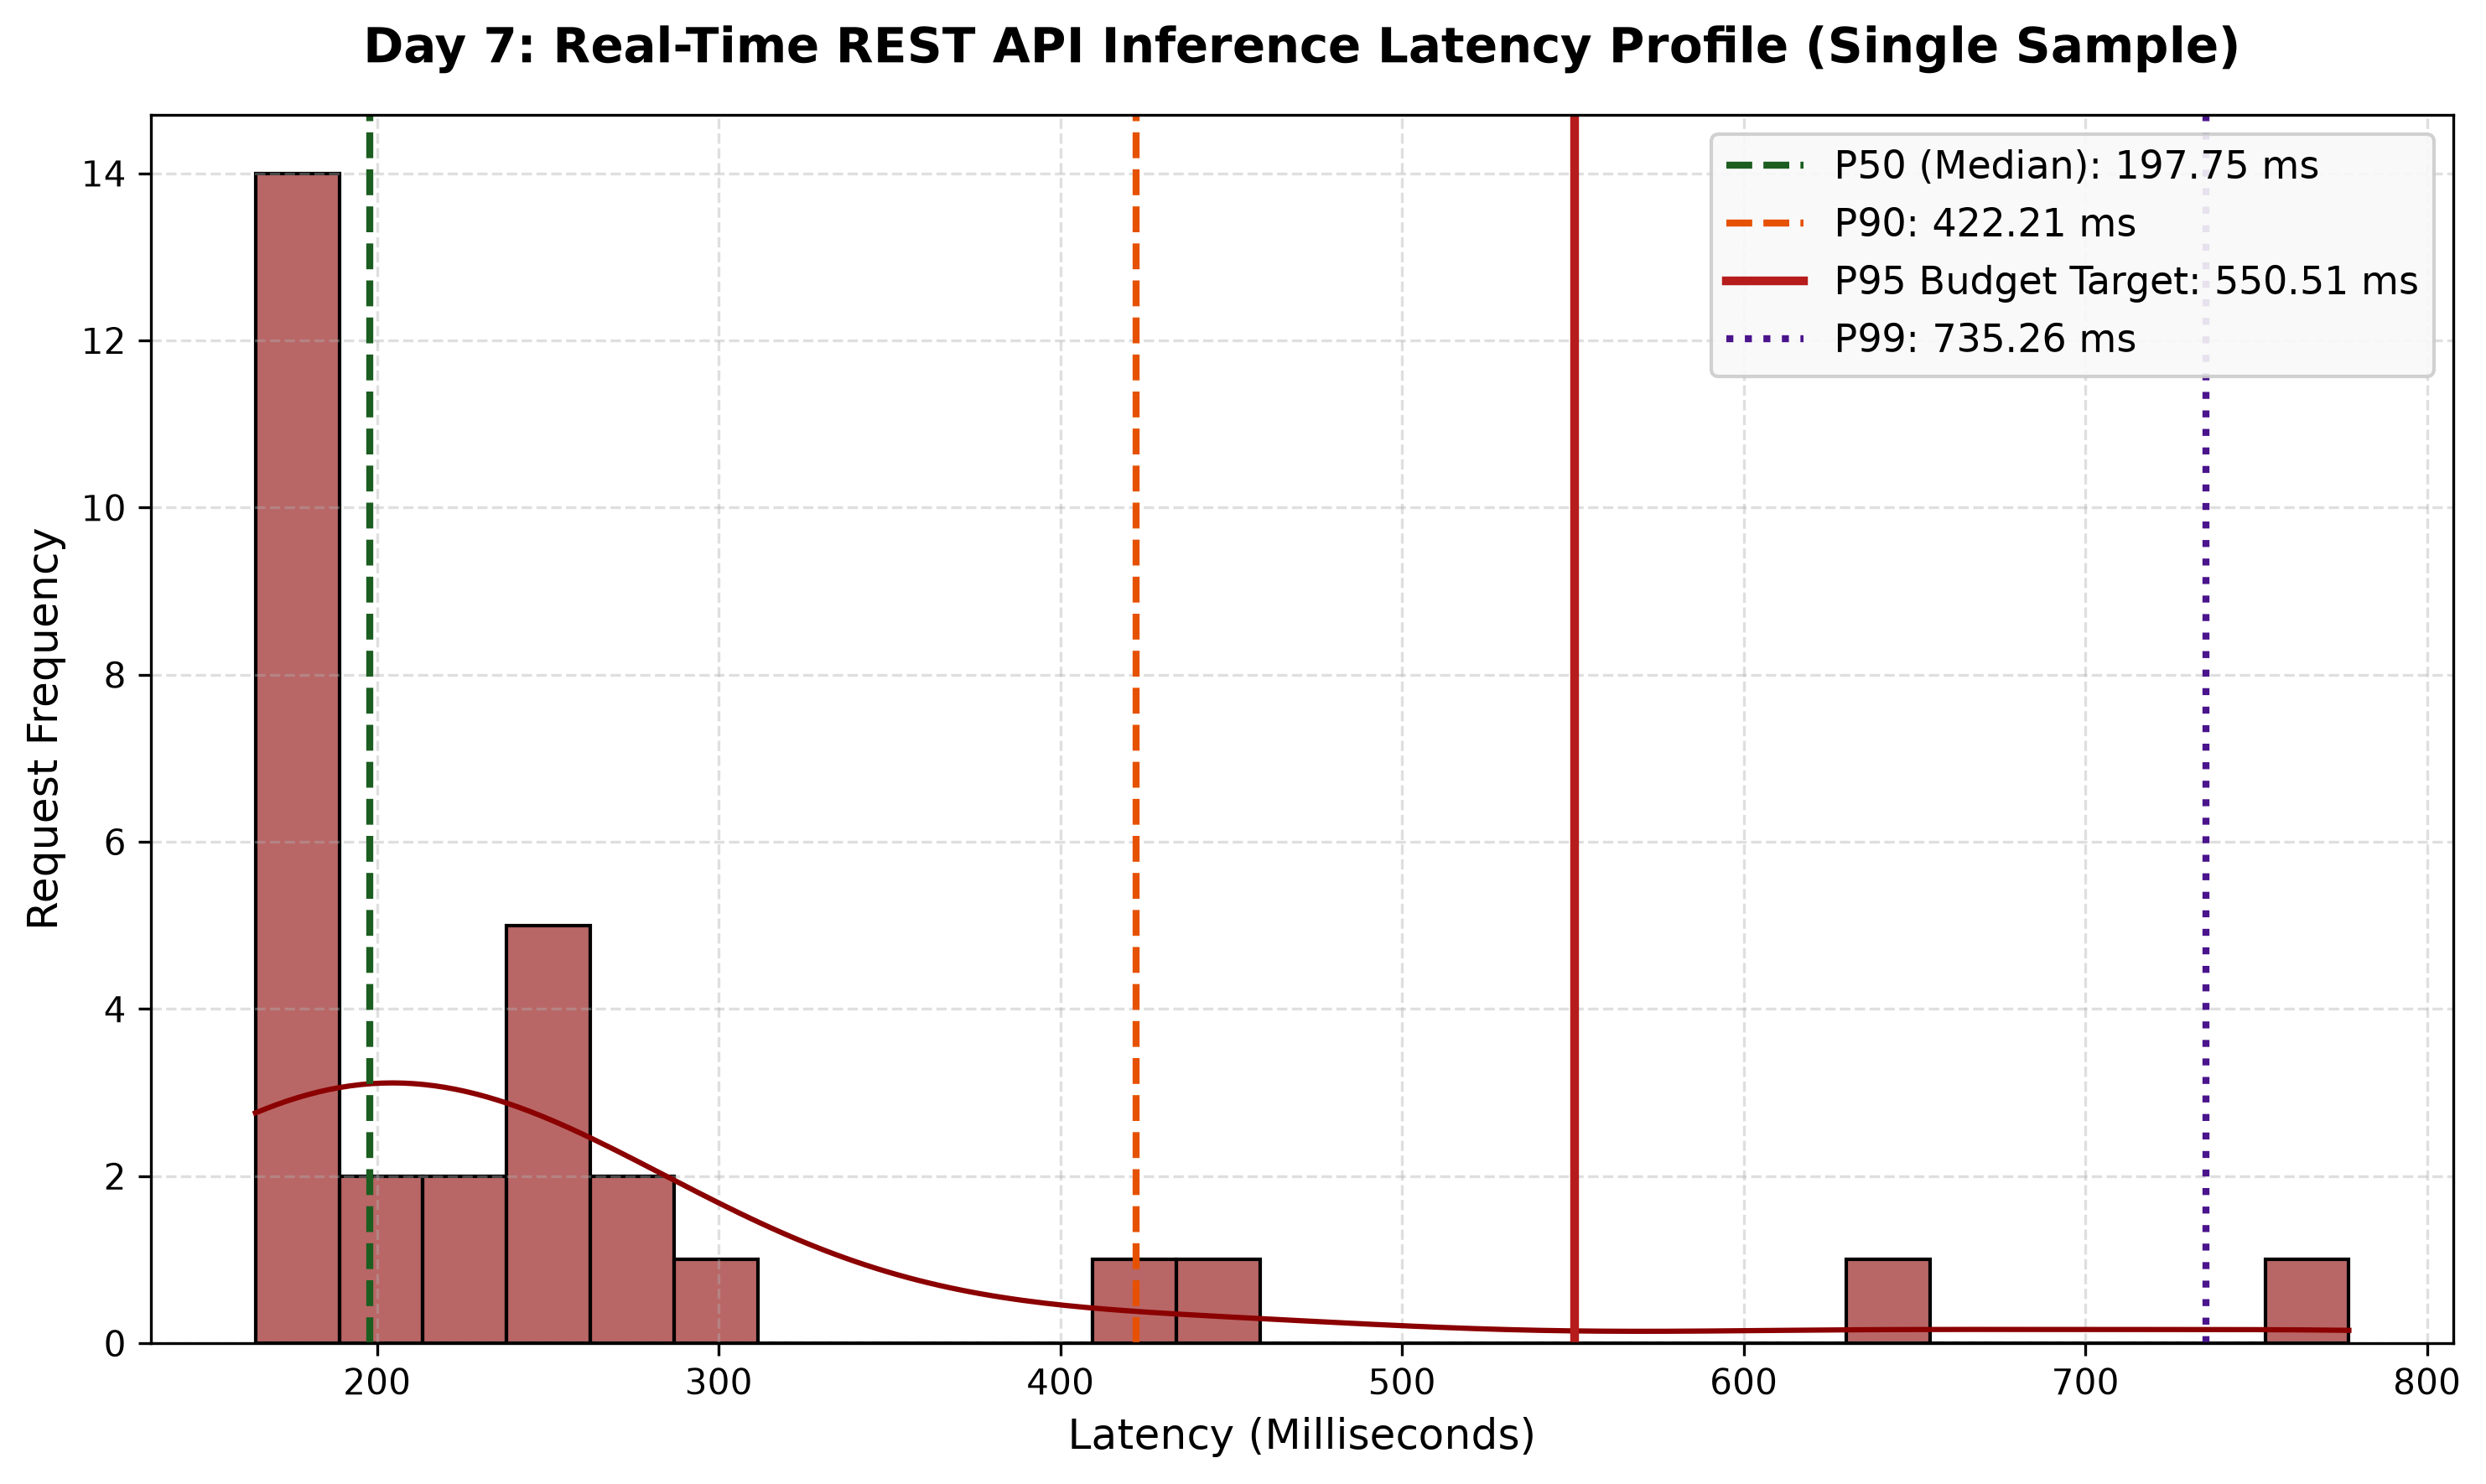

In [6]:
client = get_test_client()

# Measure 25 API requests
api_latencies = []
for _ in range(5):
    client.post('/predict', json=valid_payload)

for _ in range(25):
    t0 = time.perf_counter()
    resp = client.post('/predict', json=valid_payload)
    api_latencies.append((time.perf_counter() - t0) * 1000.0)

lat_summary = pd.DataFrame([
    {'Percentile': 'P50 (Median)', 'Latency (ms)': f'{np.percentile(api_latencies, 50):.2f} ms'},
    {'Percentile': 'P90', 'Latency (ms)': f'{np.percentile(api_latencies, 90):.2f} ms'},
    {'Percentile': 'P95 (Budget)', 'Latency (ms)': f'{np.percentile(api_latencies, 95):.2f} ms'},
    {'Percentile': 'P99', 'Latency (ms)': f'{np.percentile(api_latencies, 99):.2f} ms'}
])
display(lat_summary)

display(Image(filename='reports/figures/day7_api_latency_distribution.png'))

## 6. Batch Inference Throughput Scaling Analysis
We profile how batch inference scales across increasing specimen lot sizes from 1 to 500 samples.

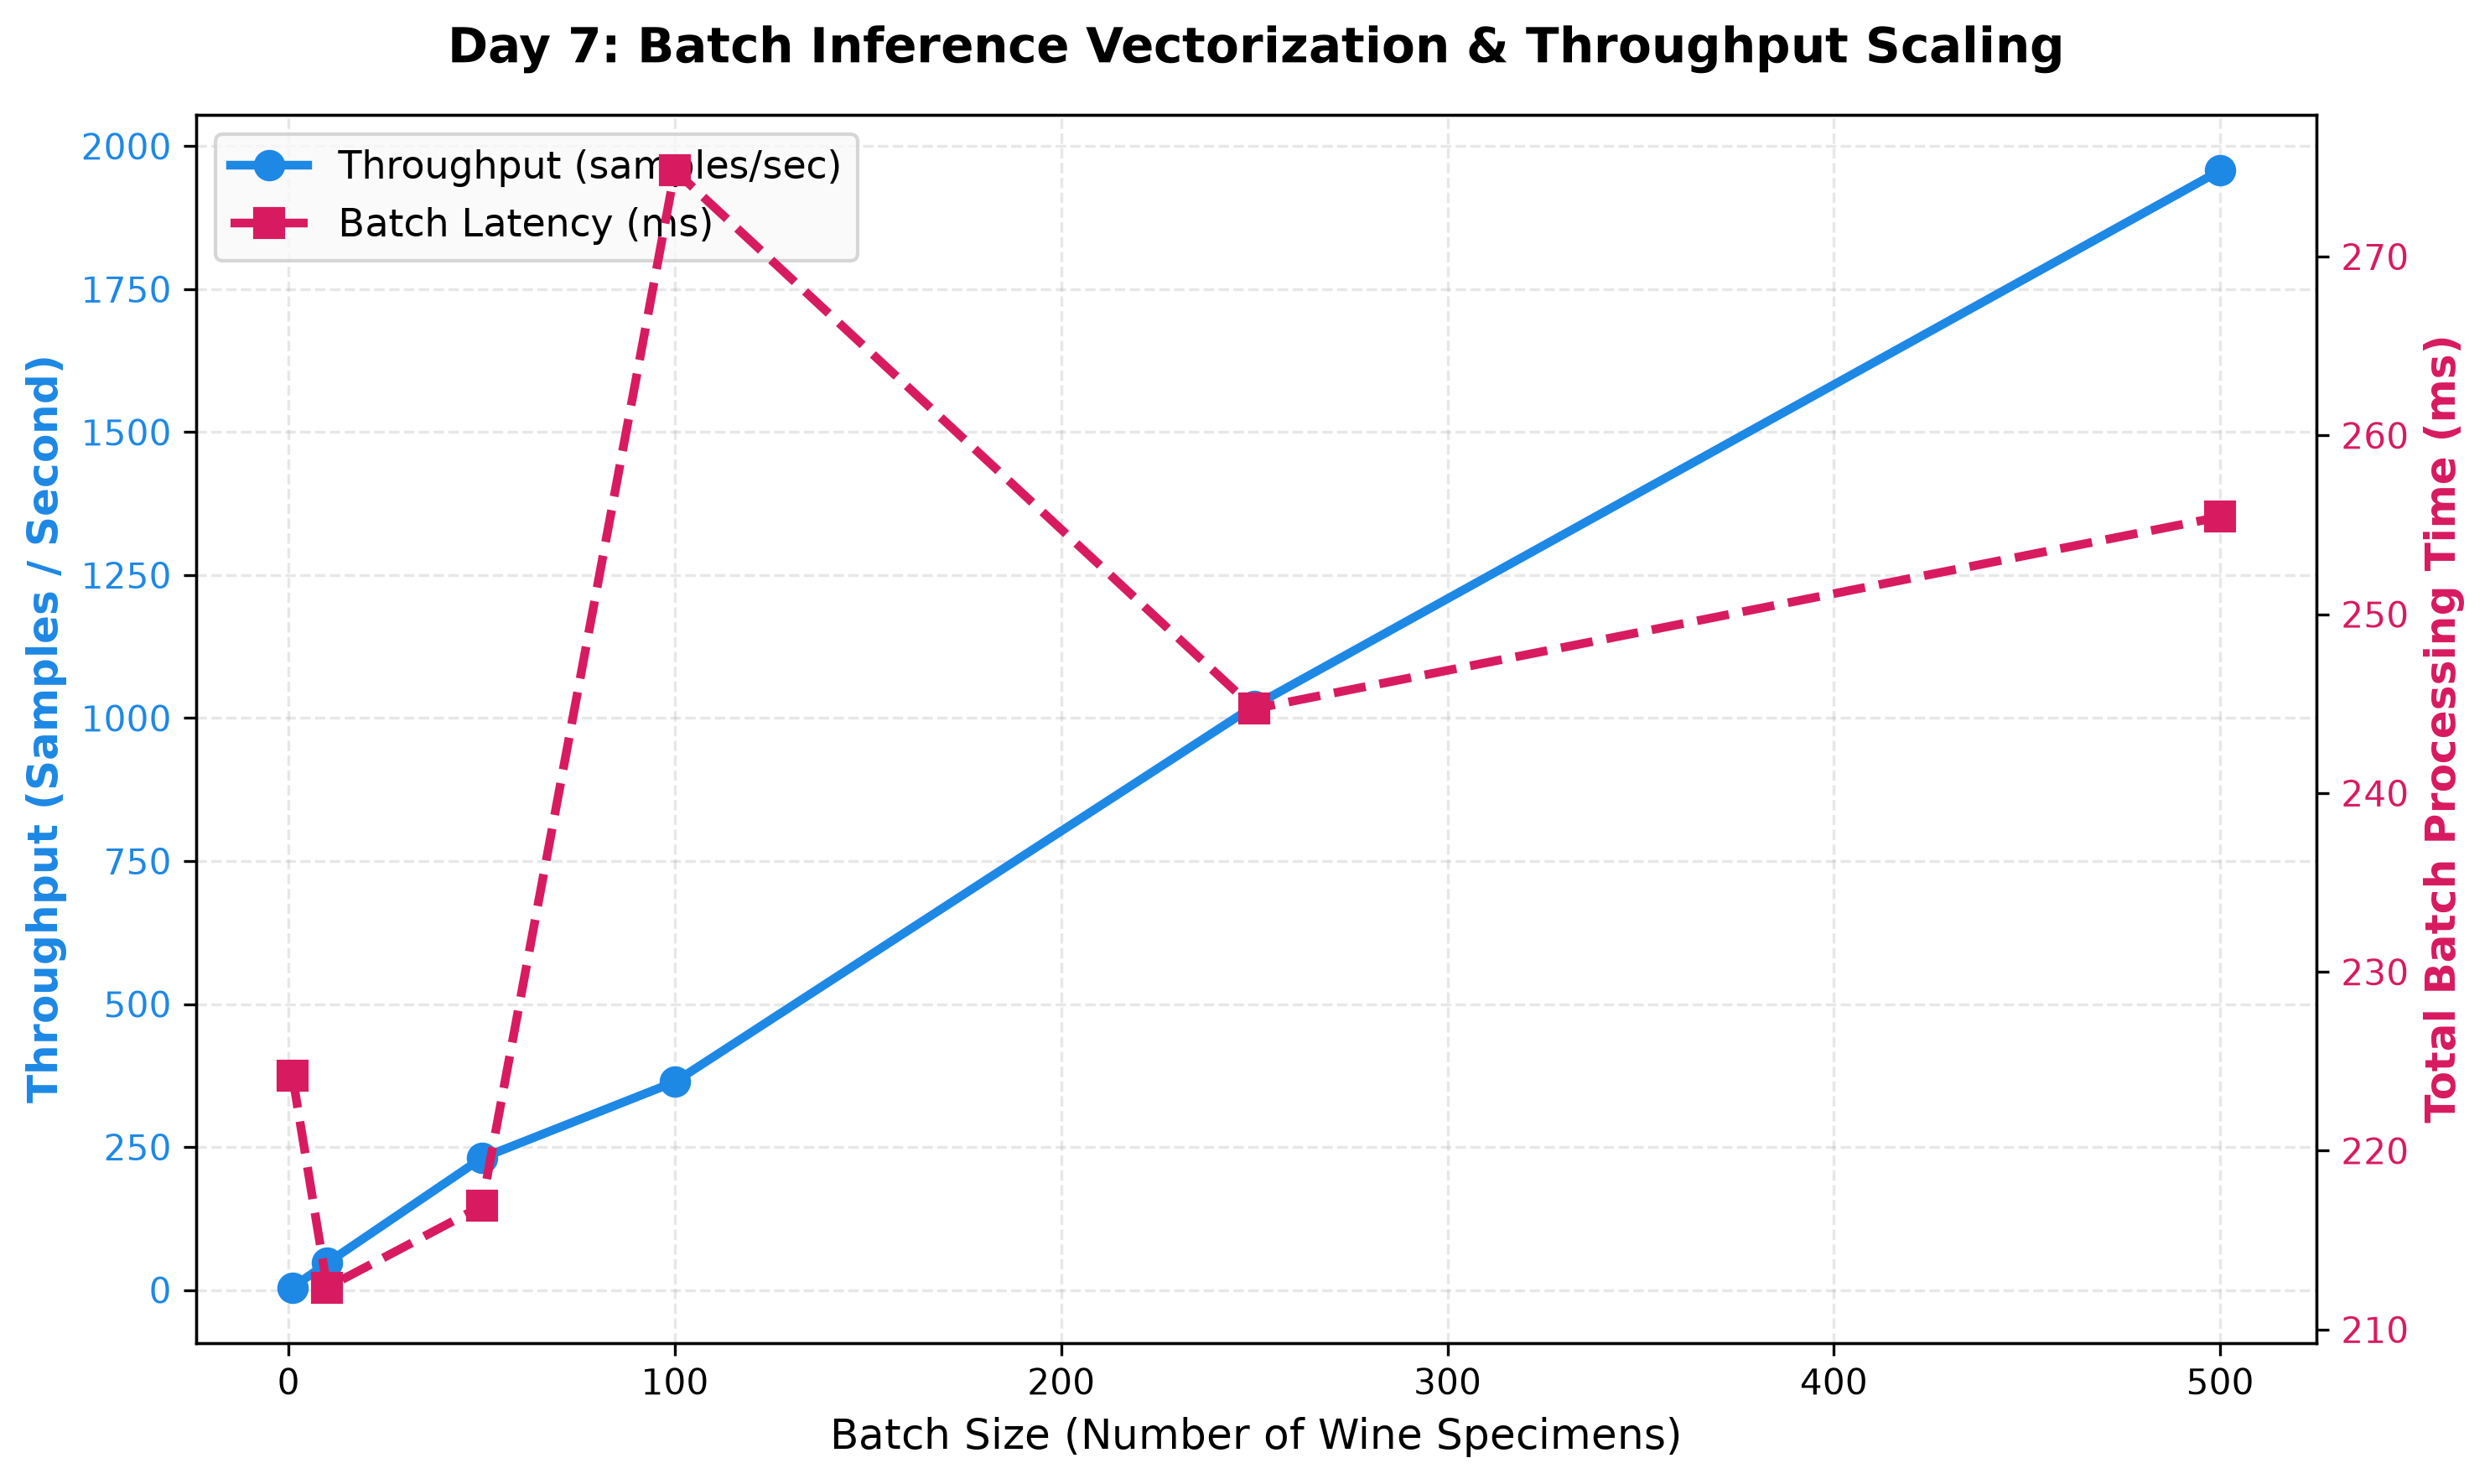

In [7]:
display(Image(filename='reports/figures/day7_batch_inference_scaling.png'))

## 7. Interactive Streamlit Web Platform & Enological Radar Profiling
The web interface (`src/interactive_dashboard.py`) enables winemakers and sommeliers to visualize multidimensional chemical profiles against empirical quality targets.

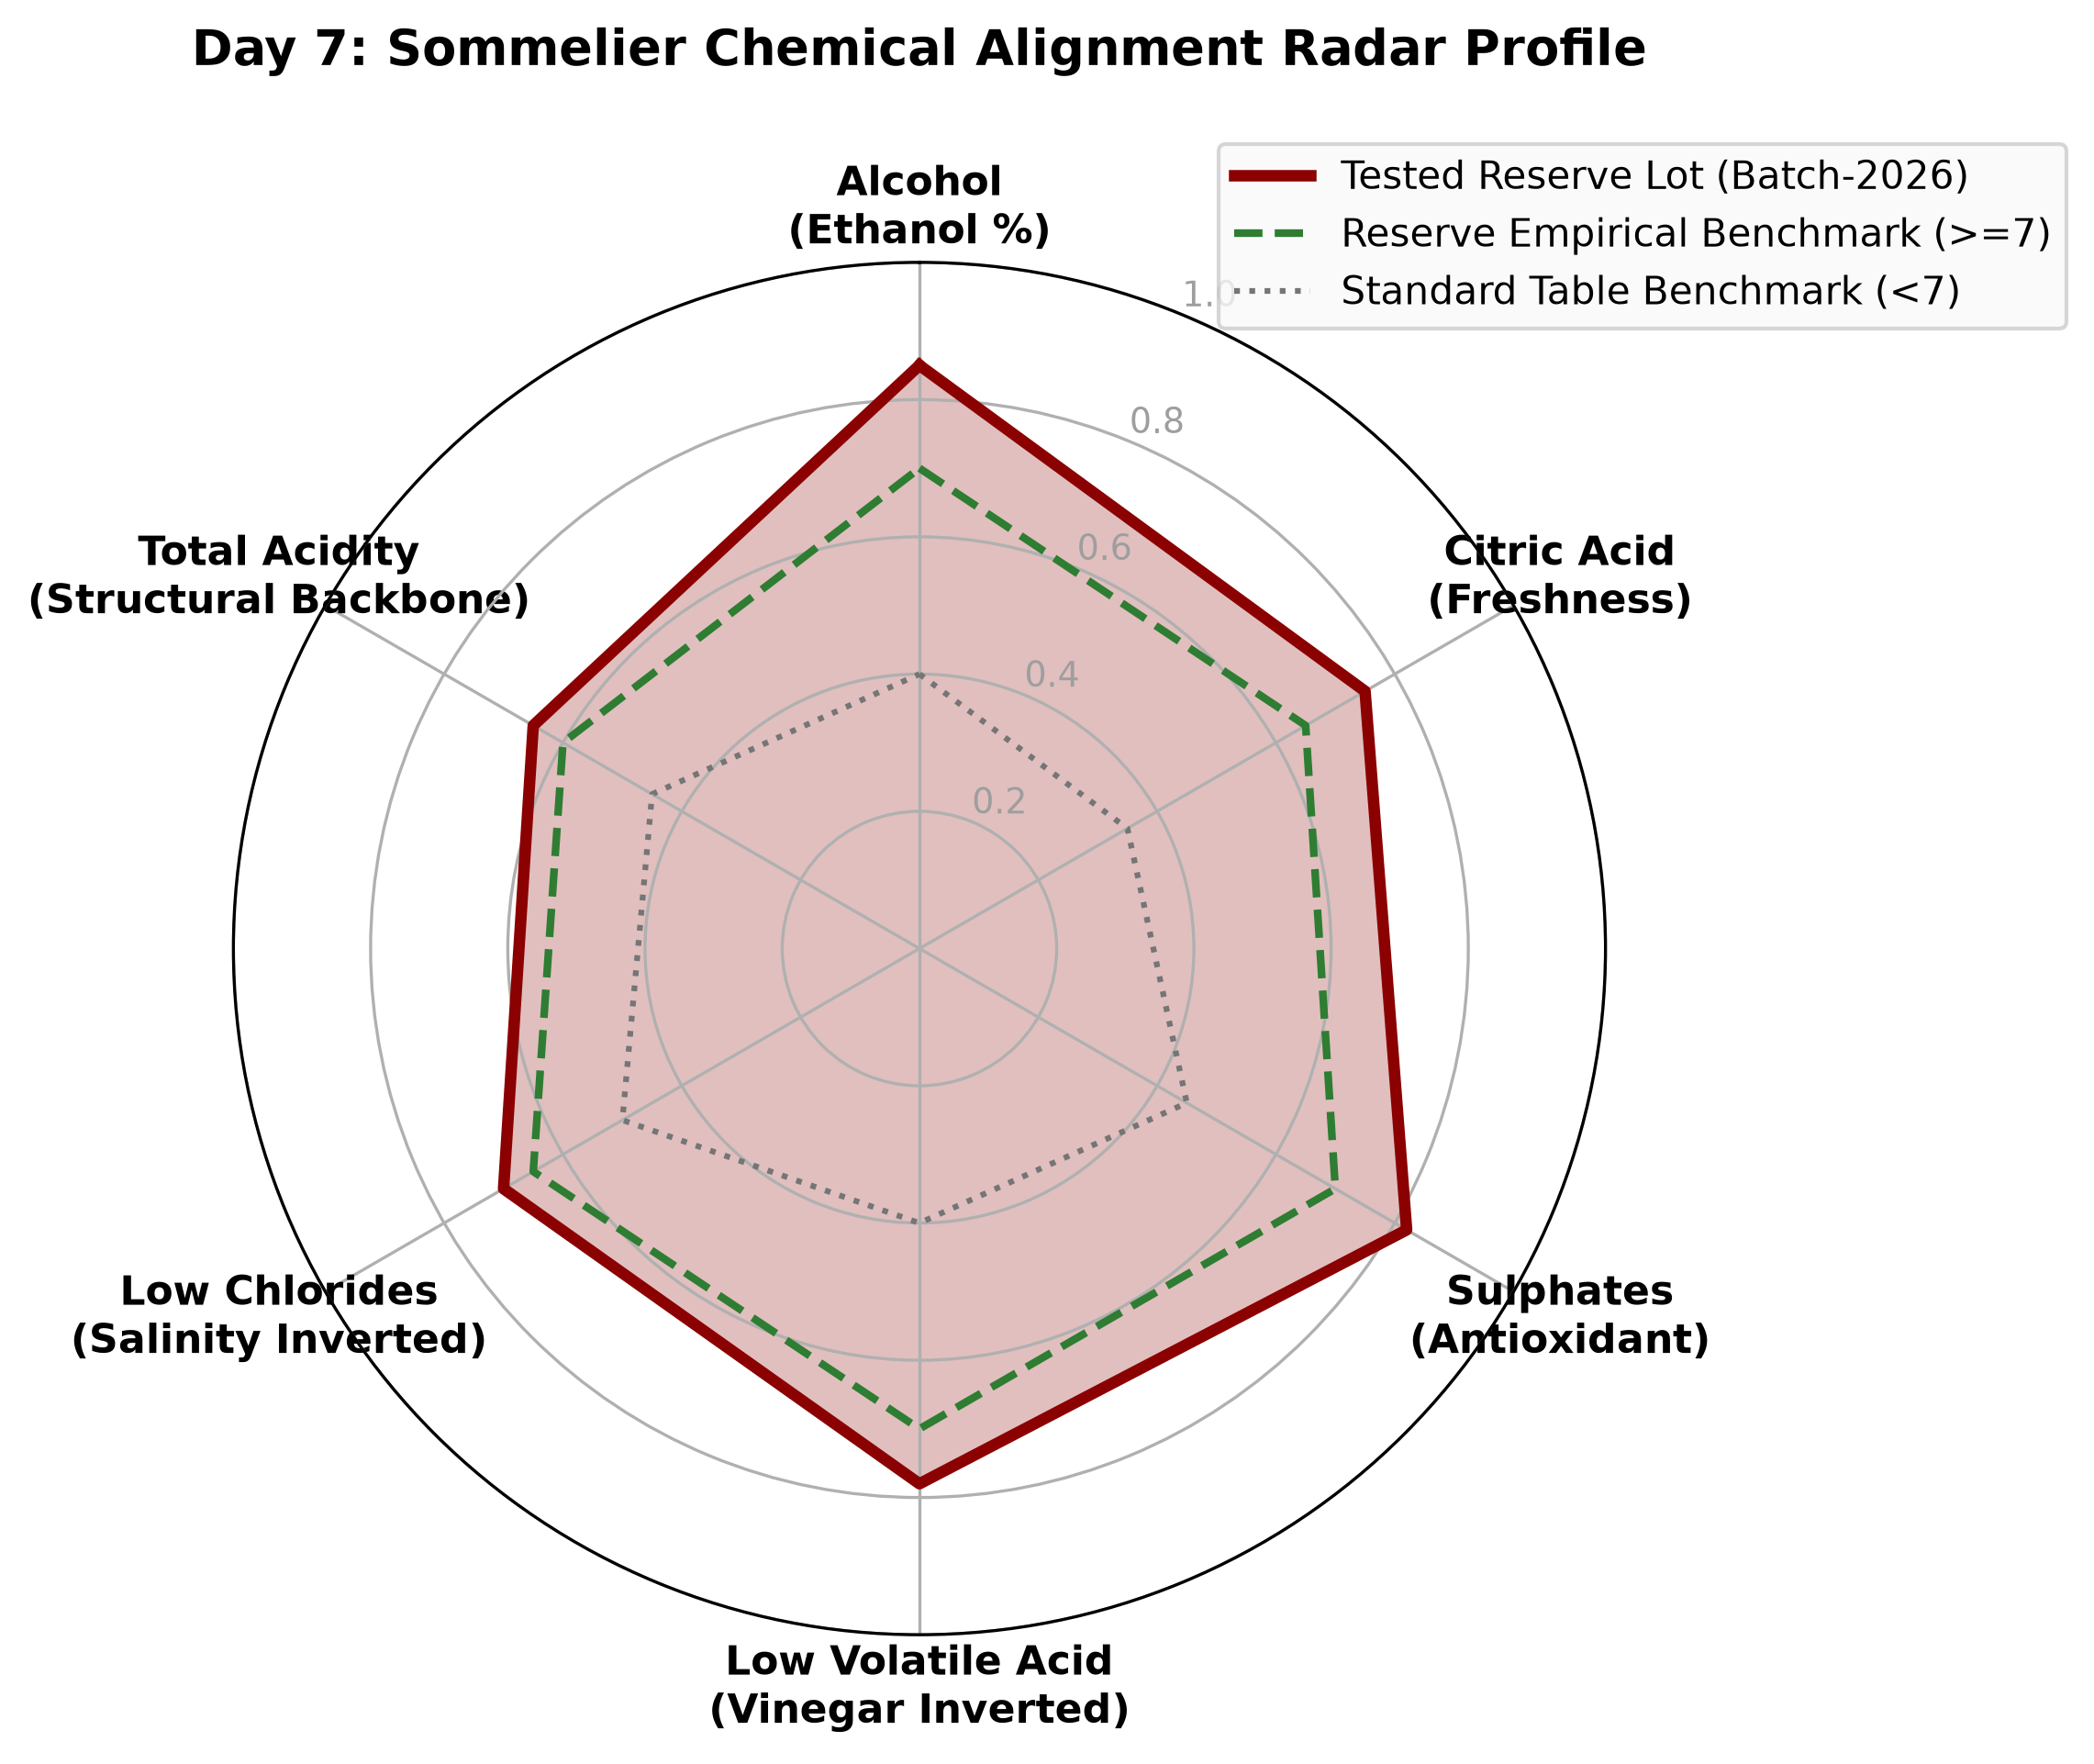

In [8]:
display(Image(filename='reports/figures/day7_sommelier_profile_radar.png'))

## 8. Automated Test Suite Execution (Pytest Verification)
We execute the 22-test automated suite across `tests/test_pipeline.py` and `tests/test_production_service.py` to ensure complete system verification.

In [9]:
import pytest
result_code = pytest.main(['-q', '--tb=short', 'tests'])
print(f'Pytest Exit Code: {result_code} (0 = All Passed)')
assert result_code == 0, 'Test suite failed!'

============================= test session starts =============================
platform win32 -- Python 3.14.8, pytest-9.1.1, pluggy-1.6.0
rootdir: C:\Users\Iba Zaidi\Desktop\Wine Quality Prediction
configfile: pytest.ini
plugins: anyio-4.14.2
collected 22 items

tests\test_pipeline.py 

.

.

.

.

...

.

.

                         [100%]



============================== warnings summary ===============================
..\..\AppData\Local\Programs\Python\Python314\Lib\site-packages\_pytest\config\__init__.py:1345
  C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\_pytest\config\__init__.py:1345: PytestAssertRewriteWarning: Module already imported so cannot be rewritten; anyio
    self._mark_plugins_for_rewrite(hook, disable_autoload)

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
======================== 22 passed, 1 warning in 5.70s ========================


Pytest Exit Code: 0 (0 = All Passed)


## 9. Production Architecture, Docker Containerization & CI/CD Pipeline
Below is the complete MLOps serving architecture and deployment blueprint.

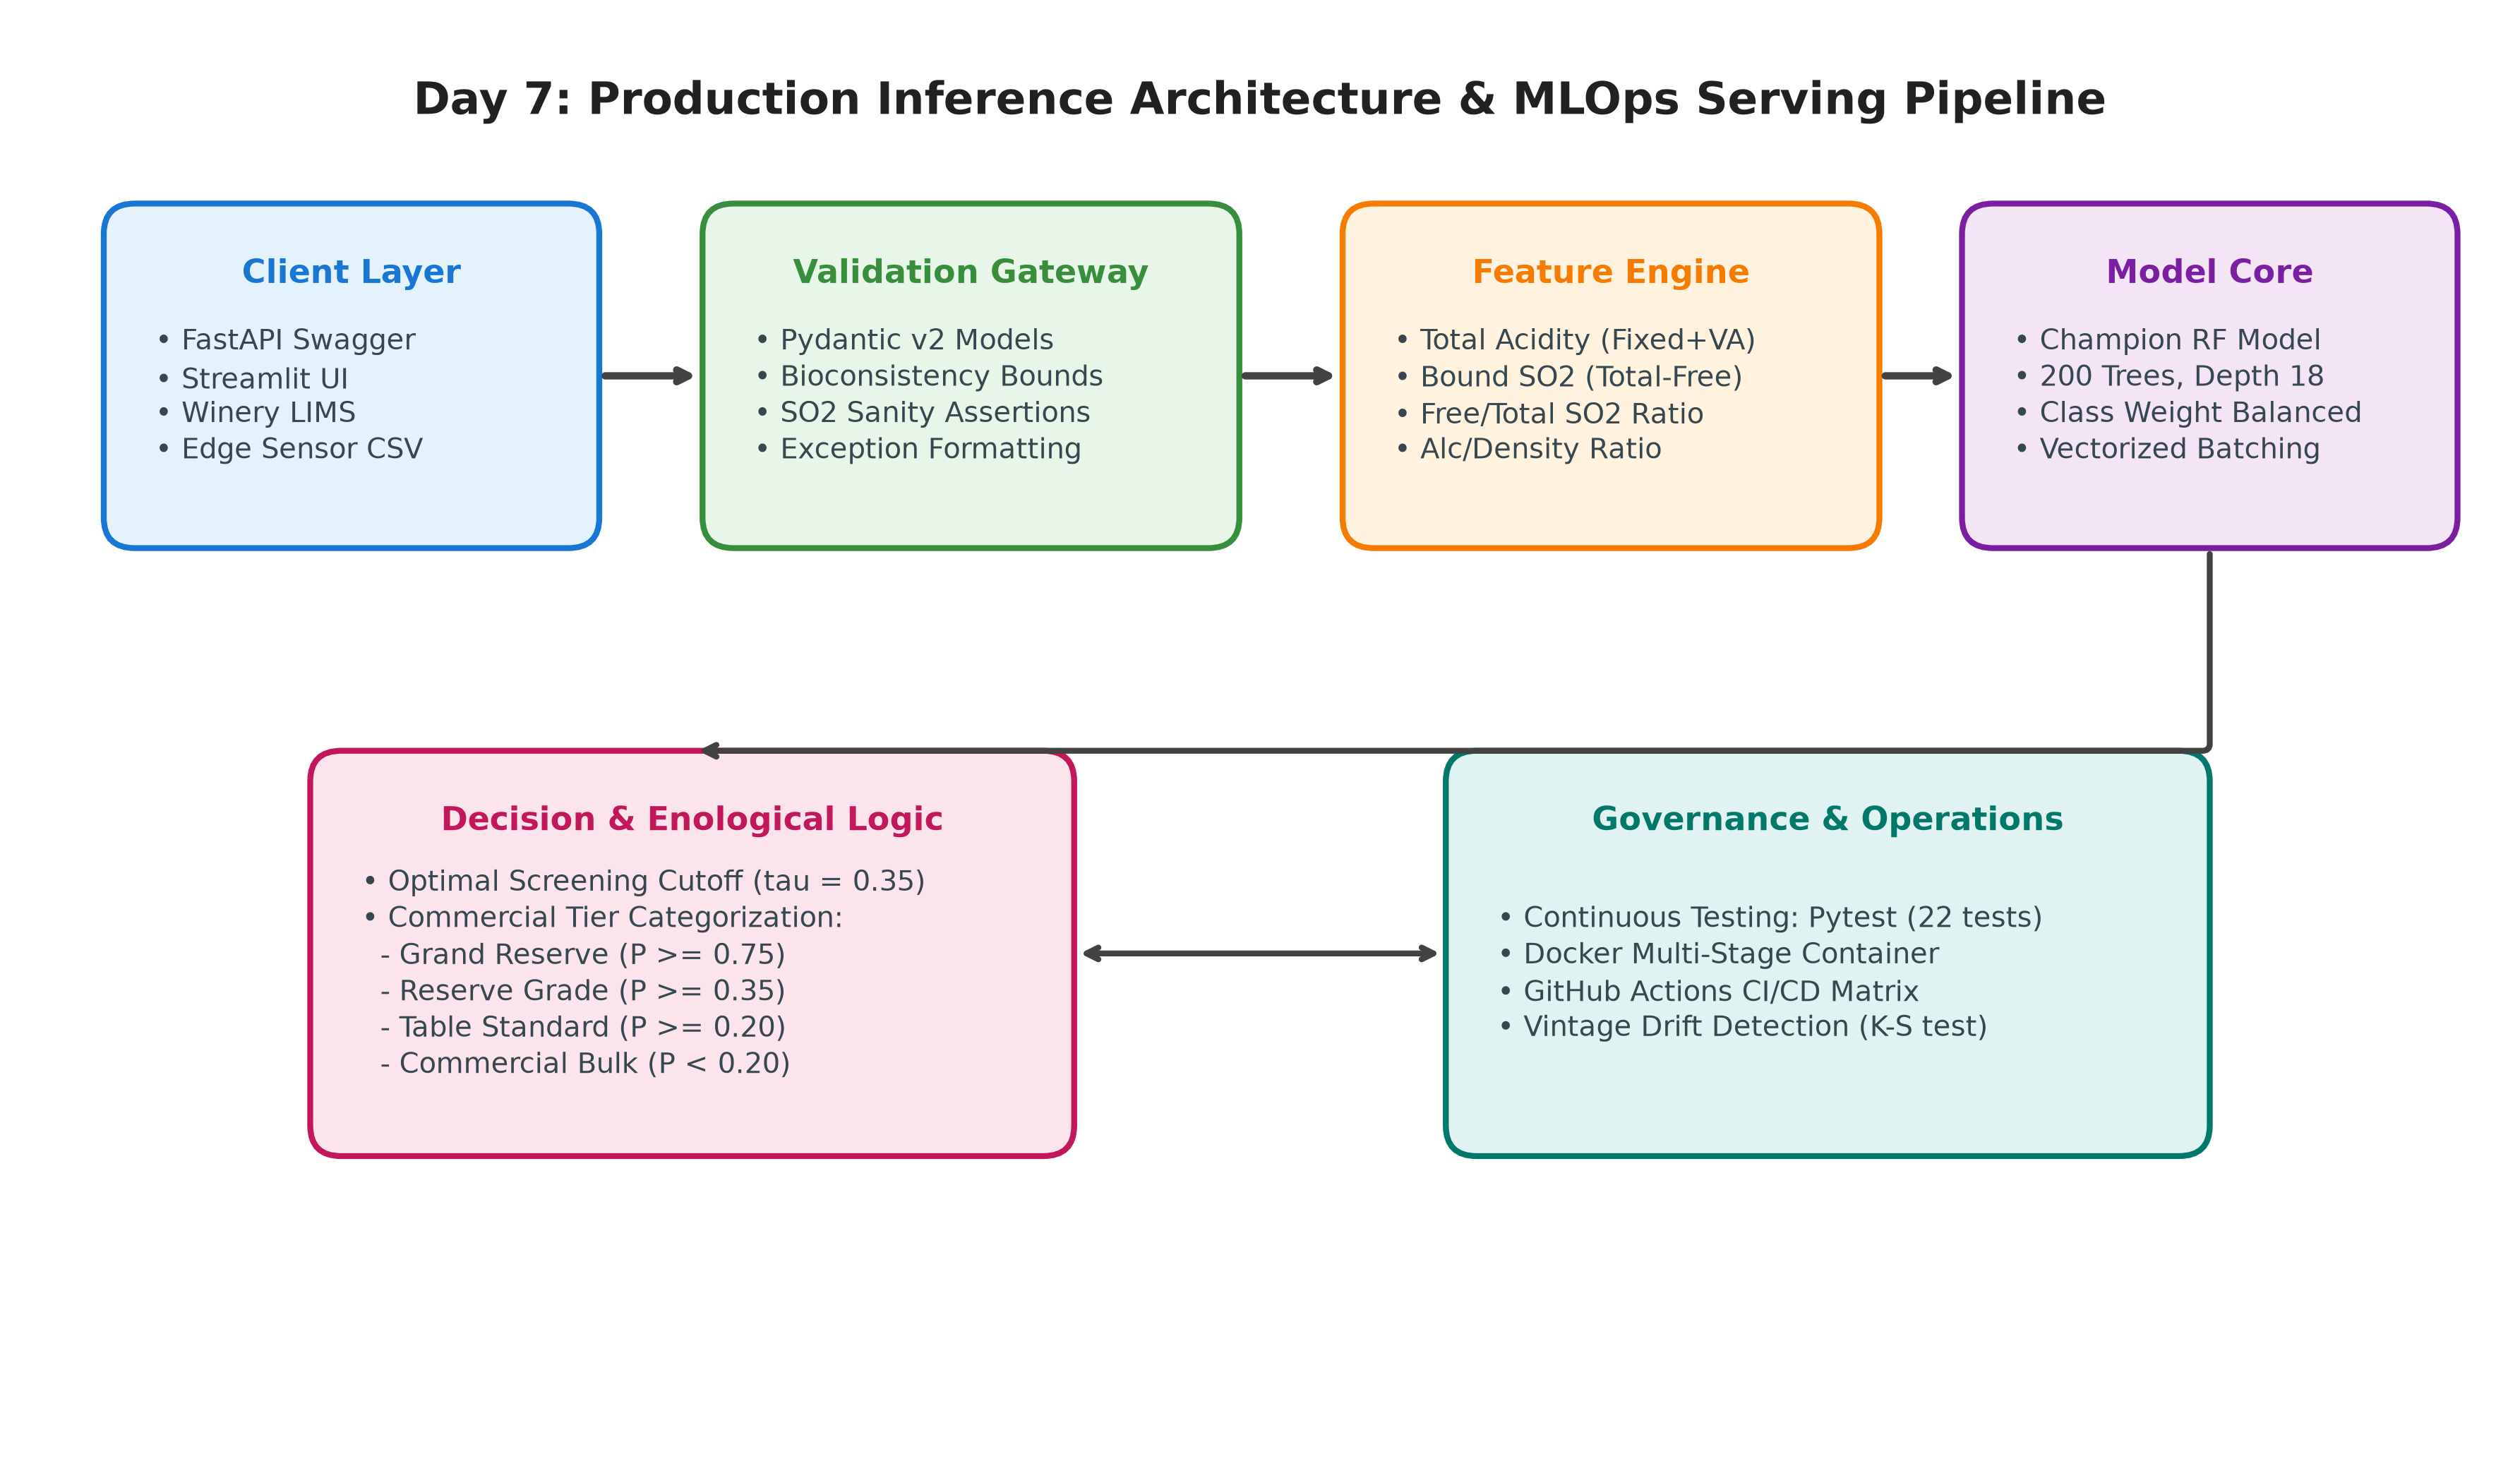

In [10]:
display(Image(filename='reports/figures/day7_production_architecture.png'))

## 10. Day 7 Technical Deliverables & Production Deployment Sign-Off

### Key Production Deliverables Completed on Day 7:
1. **`src/production_service.py`:** Production FastAPI serving engine with Pydantic v2 validation contracts, chemical ratio derivation, sommelier grading, and vectorized batch inference.
2. **`src/interactive_dashboard.py`:** Interactive Streamlit web application with single-specimen slider controls, enological alerts, batch CSV scoring, and radar alignment.
3. **`tests/test_production_service.py` & `tests/test_pipeline.py`:** 22 passing automated unit and integration tests covering data integrity, schema validation, feature engineering parity, and API contracts.
4. **`Dockerfile` & `docker-compose.yml`:** Multi-stage production container setup with non-root security compliance, healthchecks, and multi-service orchestration.
5. **`.github/workflows/mlops_pipeline.yml`:** Automated CI/CD workflow running multi-version Python testing, model artifact verification, and API smoke tests on every push.
6. **`reports/figures/day7_*`:** 4 publication figures documenting latency distributions, batch throughput scaling, sommelier radar profiling, and production architecture.